# 02 - Exploratory analysis

Before any model, I want to know what drives the entry price on a rate card. Three questions guide this notebook:

1. How is the price distributed, and does that shape change how we should model it?
2. Which rate-card attributes separate cheap lanes from expensive ones?
3. Are those differences big enough to trust, or could they be noise?

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", context="notebook")
FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

lanes = pd.read_csv("../data/processed/rate_lanes_clean.csv", parse_dates=["effective_date"])
print(f"{len(lanes):,} lanes, {lanes['contract_id'].nunique()} contracts, {lanes['customer_id'].nunique()} customers")

1,296 lanes, 54 contracts, 8 customers


## 1. The price we want to predict

In [2]:
lanes["base_rate_inr"].describe().round(1)

count    1296.0
mean      658.8
std      1121.8
min        12.2
25%        28.5
50%        38.6
75%      1382.6
max      8951.1
Name: base_rate_inr, dtype: float64

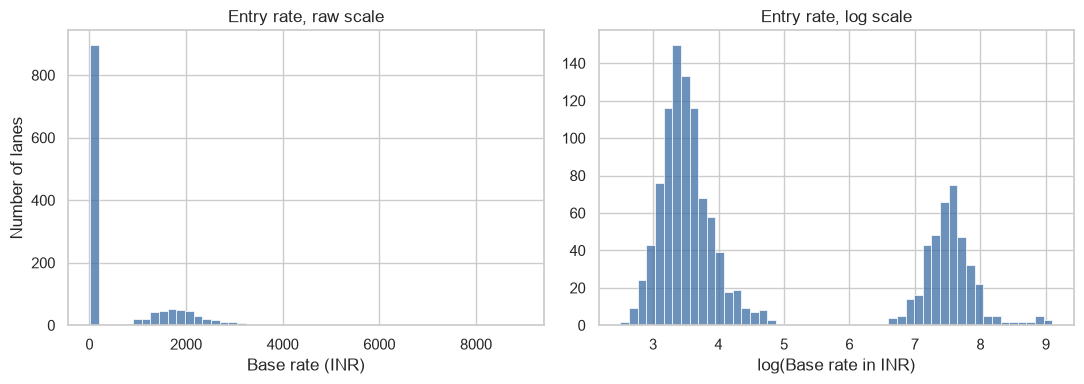

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(lanes["base_rate_inr"], bins=50, ax=axes[0], color="#3b6ea5")
axes[0].set(title="Entry rate, raw scale", xlabel="Base rate (INR)", ylabel="Number of lanes")
sns.histplot(lanes["log_base_rate"], bins=50, ax=axes[1], color="#3b6ea5")
axes[1].set(title="Entry rate, log scale", xlabel="log(Base rate in INR)", ylabel="")
plt.tight_layout()
fig.savefig(FIG_DIR / "01_rate_distribution.png", dpi=150)
plt.show()

On the raw scale almost every lane is bunched up at the left with a long tail of very expensive ones. The log scale shows why: there are two separate humps. One is the cheap group around INR 30, the other the expensive group in the thousands. A single straight line would struggle with that, so the model will work on the log of the rate.

## 2. Which attributes separate the two groups?

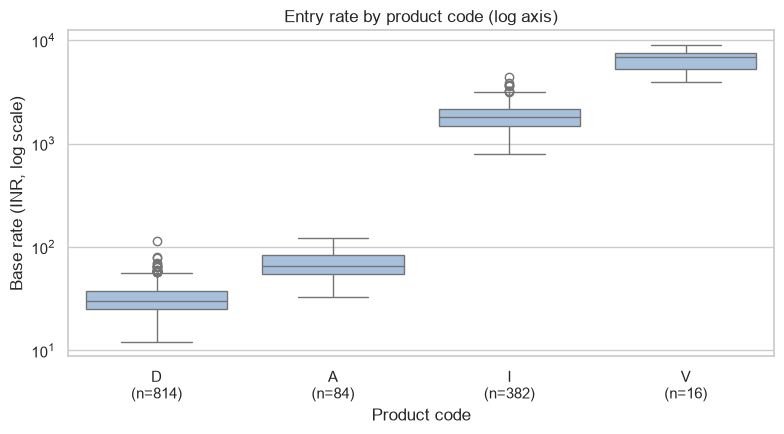

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.5))
order = lanes.groupby("product_code")["base_rate_inr"].median().sort_values().index
sns.boxplot(data=lanes, x="product_code", y="base_rate_inr", order=order, ax=ax, color="#9ec1e6")
ax.set_yscale("log")
ax.set(title="Entry rate by product code (log axis)", xlabel="Product code", ylabel="Base rate (INR, log scale)")
counts = lanes["product_code"].value_counts()
ax.set_xticks(range(len(order)))
ax.set_xticklabels([f"{p}\n(n={counts[p]})" for p in order])
plt.tight_layout()
fig.savefig(FIG_DIR / "02_rate_by_product.png", dpi=150)
plt.show()

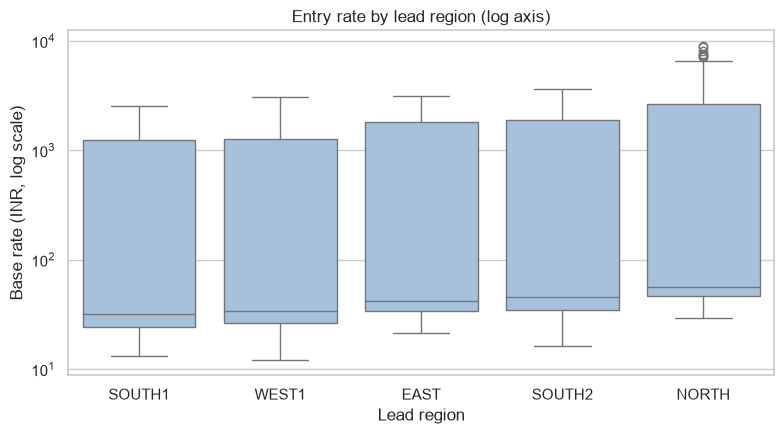

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5))
order = lanes.groupby("lead_region")["base_rate_inr"].median().sort_values().index
sns.boxplot(data=lanes, x="lead_region", y="base_rate_inr", order=order, ax=ax, color="#9ec1e6")
ax.set_yscale("log")
ax.set(title="Entry rate by lead region (log axis)", xlabel="Lead region", ylabel="Base rate (INR, log scale)")
plt.tight_layout()
fig.savefig(FIG_DIR / "03_rate_by_region.png", dpi=150)
plt.show()

Product code is the loudest signal: one product sits far above the rest. The region chart needs care. The NORTH region looks expensive, and the product mix inside each region (next cell) explains part of that: NORTH is the only region carrying product `V`, the priciest one. The test in section 4 checks whether a regional gap remains once product `I` is set aside.

In [6]:
mix = pd.crosstab(lanes["lead_region"], lanes["product_code"], normalize="index").round(2)
mix

product_code,A,D,I,V
lead_region,,,,
EAST,0.00,0.74,0.26,0.00
NORTH,0.00,0.67,0.17,0.17
SOUTH1,0.08,0.61,0.31,0.00
SOUTH2,0.08,0.59,0.33,0.00
WEST1,0.07,0.63,0.30,0.00


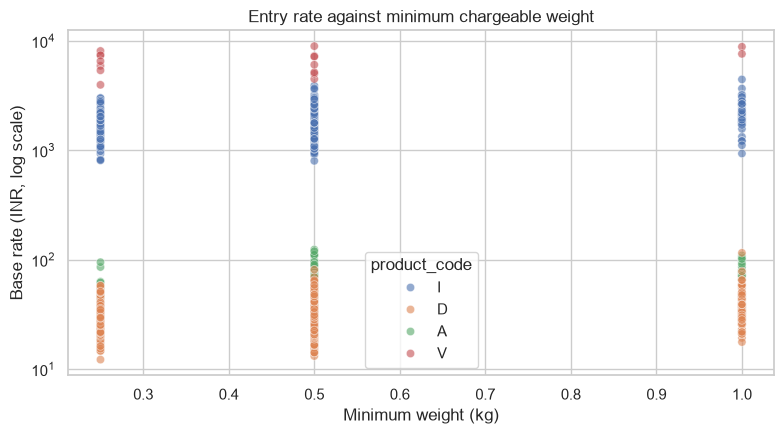

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.scatterplot(data=lanes, x="min_weight_kg", y="base_rate_inr", hue="product_code",
                alpha=0.6, ax=ax)
ax.set_yscale("log")
ax.set(title="Entry rate against minimum chargeable weight", xlabel="Minimum weight (kg)",
       ylabel="Base rate (INR, log scale)")
plt.tight_layout()
fig.savefig(FIG_DIR / "04_rate_vs_min_weight.png", dpi=150)
plt.show()

Minimum weight only takes a handful of values (0.25, 0.5 and 1 kg), so a scatter plot is not very informative. It is here to show that no hidden trend lives in that column. Within one product, price barely moves with it.

## 3. Correlations between numeric columns

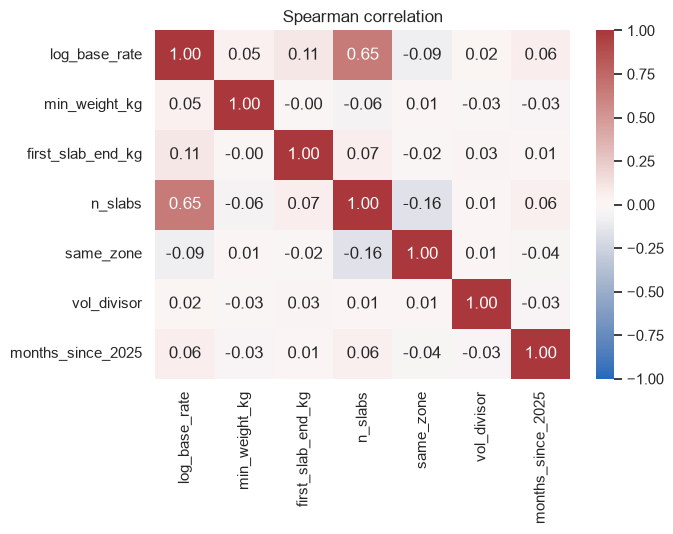

In [8]:
numeric = ["log_base_rate", "min_weight_kg", "first_slab_end_kg", "n_slabs", "same_zone",
           "vol_divisor", "months_since_2025"]
corr = lanes[numeric].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Spearman correlation")
plt.tight_layout()
fig.savefig(FIG_DIR / "05_correlation_heatmap.png", dpi=150)
plt.show()

Spearman is used because it ranks values rather than assuming a straight-line relationship, which suits the two-hump price shape.

## 4. Are the differences real? Inferential checks

In [9]:
domestic_like = lanes[lanes["product_code"] != "I"]
intl_like = lanes[lanes["product_code"] == "I"]

u, p_mw = stats.mannwhitneyu(intl_like["base_rate_inr"], domestic_like["base_rate_inr"], alternative="greater")
effect = intl_like["log_base_rate"].median() - domestic_like["log_base_rate"].median()
print(f"Product I vs others: Mann-Whitney p = {p_mw:.2e}")
print(f"Median product I rate is {np.exp(effect):.0f}x the median of the others")

Product I vs others: Mann-Whitney p = 7.24e-166
Median product I rate is 56x the median of the others


In [10]:
# is there still a regional difference once product I is set aside?
groups = [g["log_base_rate"].values for _, g in domestic_like.groupby("lead_region") if len(g) >= 5]
h, p_kw = stats.kruskal(*groups)
print(f"Region effect outside product I: Kruskal-Wallis H = {h:.1f}, p = {p_kw:.2e}")
print(domestic_like.groupby("lead_region")["base_rate_inr"].agg(["count", "median"]).round(1))

Region effect outside product I: Kruskal-Wallis H = 254.9, p = 5.60e-54
             count  median
lead_region               
EAST            81    36.6
NORTH           80    51.9
SOUTH1         192    26.6
SOUTH2         191    37.5
WEST1          370    28.9


In [11]:
rho, p_rho = stats.spearmanr(lanes["n_slabs"], lanes["log_base_rate"])
print(f"Number of slabs vs rate: Spearman rho = {rho:.2f}, p = {p_rho:.2e}")
print("Mean slabs per lane, product I vs others:", intl_like["n_slabs"].mean().round(1), "vs", domestic_like["n_slabs"].mean().round(1))

same = lanes[lanes["same_zone"] == 1]["log_base_rate"]
diff = lanes[lanes["same_zone"] == 0]["log_base_rate"]
u2, p_same = stats.mannwhitneyu(same, diff)
print(f"Same-zone vs cross-zone lanes: p = {p_same:.2g}")

Number of slabs vs rate: Spearman rho = 0.65, p = 9.43e-159
Mean slabs per lane, product I vs others: 32.5 vs 2.9
Same-zone vs cross-zone lanes: p = 0.0013


### How to read these tests

I use rank-based tests because the rate distribution is badly skewed and a t-test would mislead. With more than a thousand lanes almost any difference will look significant, so the size of the gap (medians, ratios) matters more than the p-value.

One caution: lanes inside one contract are not independent. Two lanes from the same customer's price list tend to move together, which is why the modelling notebook keeps whole customers together when it splits the data.

## 5. Contracts differ from each other

In [12]:
per_contract = (lanes.groupby("contract_id")["log_base_rate"]
                .agg(["count", "median", "std"]).sort_values("count", ascending=False))
print(per_contract.describe().round(2))

       count  median    std
count  54.00   54.00  54.00
mean   24.00    3.81   1.79
std     6.24    0.81   0.39
min    15.00    3.15   0.24
25%    19.00    3.53   1.80
50%    24.00    3.62   1.91
75%    26.00    3.79   1.99
max    50.00    7.88   2.22


The table holds 54 contracts but only 8 customers, and one customer owns close to half of all lanes. Contracts from the same customer look alike, so a model could learn a customer by heart. The modelling notebook therefore splits by customer.

## What carries into modelling

- Model the **log** of the rate.
- Product code is the strongest signal; zone pairs and rate-card structure add detail.
- Keep each customer entirely in train or entirely in test.
- Keep the expensive lanes. They are the real business, not noise.

Next: `03_modelling.ipynb`.